# Setup

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df,
                                                       df_with_ground_truth_as_kind_of_model)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

https://mlflow.cropresilience.org


In [3]:
simulation_run_id_to_use = "cb55af6d44604c9395e9f3e9c5e54692"

run = mlflow.get_run(simulation_run_id_to_use)

params = run.data.params
print(params)
print(run.data.tags.get('mlflow.source.git.commit'))

{'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '2', 'noise_level': 'ALLNOISE', 'seed': '174'}
None


In [4]:
parent_run_id_search_string = f"tags.mlflow.parentRunId= '{simulation_run_id_to_use}'" 
runs_to_download = mlflow.search_runs(filter_string=parent_run_id_search_string, output_format="list")

In [ ]:
len(runs_to_download)

In [ ]:
runs_to_download[0].data.params

In [5]:
raw_df_download = create_tidy_df_from_mlflow_runs(runs_to_download)
with_model_name = add_model_name_to_df(raw_df_download)

2026-02-19 11:04:49,336 - INFO - Downloading artifacts for run 8ad1eb20acec412abf07f85346a5de71


2026-02-19 11:04:50,463 - INFO - Downloading artifacts for run 326ff90e12aa4c2faaffde13363f4c9d


2026-02-19 11:04:51,365 - INFO - Downloading artifacts for run 52f5093164c44d2ca08a5f30121b8867


2026-02-19 11:04:52,252 - INFO - Downloading artifacts for run a52ccfd2c5954120934afd0caaf766a1


2026-02-19 11:04:53,133 - INFO - Downloading artifacts for run ef5cad2dfde2413f971a6800768c28eb


2026-02-19 11:04:54,061 - INFO - Downloading artifacts for run 00a3fd02c28a481ba71068bc86324a90


2026-02-19 11:04:54,947 - INFO - Getting model name for run_id 8ad1eb20acec412abf07f85346a5de71
2026-02-19 11:04:55,097 - INFO - Getting model name for run_id 326ff90e12aa4c2faaffde13363f4c9d
2026-02-19 11:04:55,244 - INFO - Getting model name for run_id 52f5093164c44d2ca08a5f30121b8867
2026-02-19 11:04:55,390 - INFO - Getting model name for run_id a52ccfd2c5954120934afd0caaf766a1
2026-02-19 11:04:55,535 - INFO - Getting model name for run_id ef5cad2dfde2413f971a6800768c28eb
2026-02-19 11:04:55,681 - INFO - Getting model name for run_id 00a3fd02c28a481ba71068bc86324a90


## Make subsets of data for plotting

In [6]:
# Split into Single and Double knockout
tidy_df_single_ko, tidy_df_double_ko = split_df_into_single_and_double_ko(with_model_name)
tidy_df_single_ko['condition'].value_counts()

condition
KO: Node_3. Env: None     2268
KO: Node_17. Env: None    2268
KO: Node_2. Env: None     2268
KO: Node_7. Env: None     2268
KO: Node_0. Env: None     2268
KO: Node_18. Env: None    2268
KO: Node_8. Env: None     2268
KO: Node_4. Env: None     2268
KO: Node_10. Env: None    2100
KO: Node_19. Env: None    2100
KO: Node_5. Env: None     2100
KO: Node_14. Env: None    2100
KO: Node_11. Env: None    2100
KO: Node_1. Env: None     2100
KO: Node_13. Env: None    2100
KO: Node_9. Env: None     2100
KO: Node_16. Env: None    2100
KO: Node_15. Env: None    2100
KO: Node_12. Env: None    2100
KO: Node_6. Env: None     2100
Name: count, dtype: int64

In [ ]:
tidy_df_single_ko[DfColumnNames.MODEL_COL].value_counts()

In [7]:
def df_selection_function(df):
    node_index_regex = '|'.join([f'{i}' for i in range(4)])
    genes_to_show_regex = rf"Node_(?:{node_index_regex})(?:[.,]|$)"

    models_to_show = ["PhoenixAddAndProdLayers", "PyTorchODE", DfColumnNames.GROUND_TRUTH_COL, "HybridModel"]
    models_to_show_regex = "|".join(models_to_show)

    index_to_select = ((df[DfColumnNames.GENE_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.CONDITION_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.MODEL_COL].str.contains(models_to_show_regex)))
    filtered_df =  df[index_to_select]
    assert len(filtered_df), 'Filtered dataframe is empty'
    return filtered_df

In [ ]:
df_selection_function(tidy_df_single_ko).sum()

In [8]:
filtered_df_single_ko = df_selection_function(tidy_df_single_ko)
filtered_df_double_ko = df_selection_function(tidy_df_double_ko)

# Plotting

## Lineplots

### Single KO

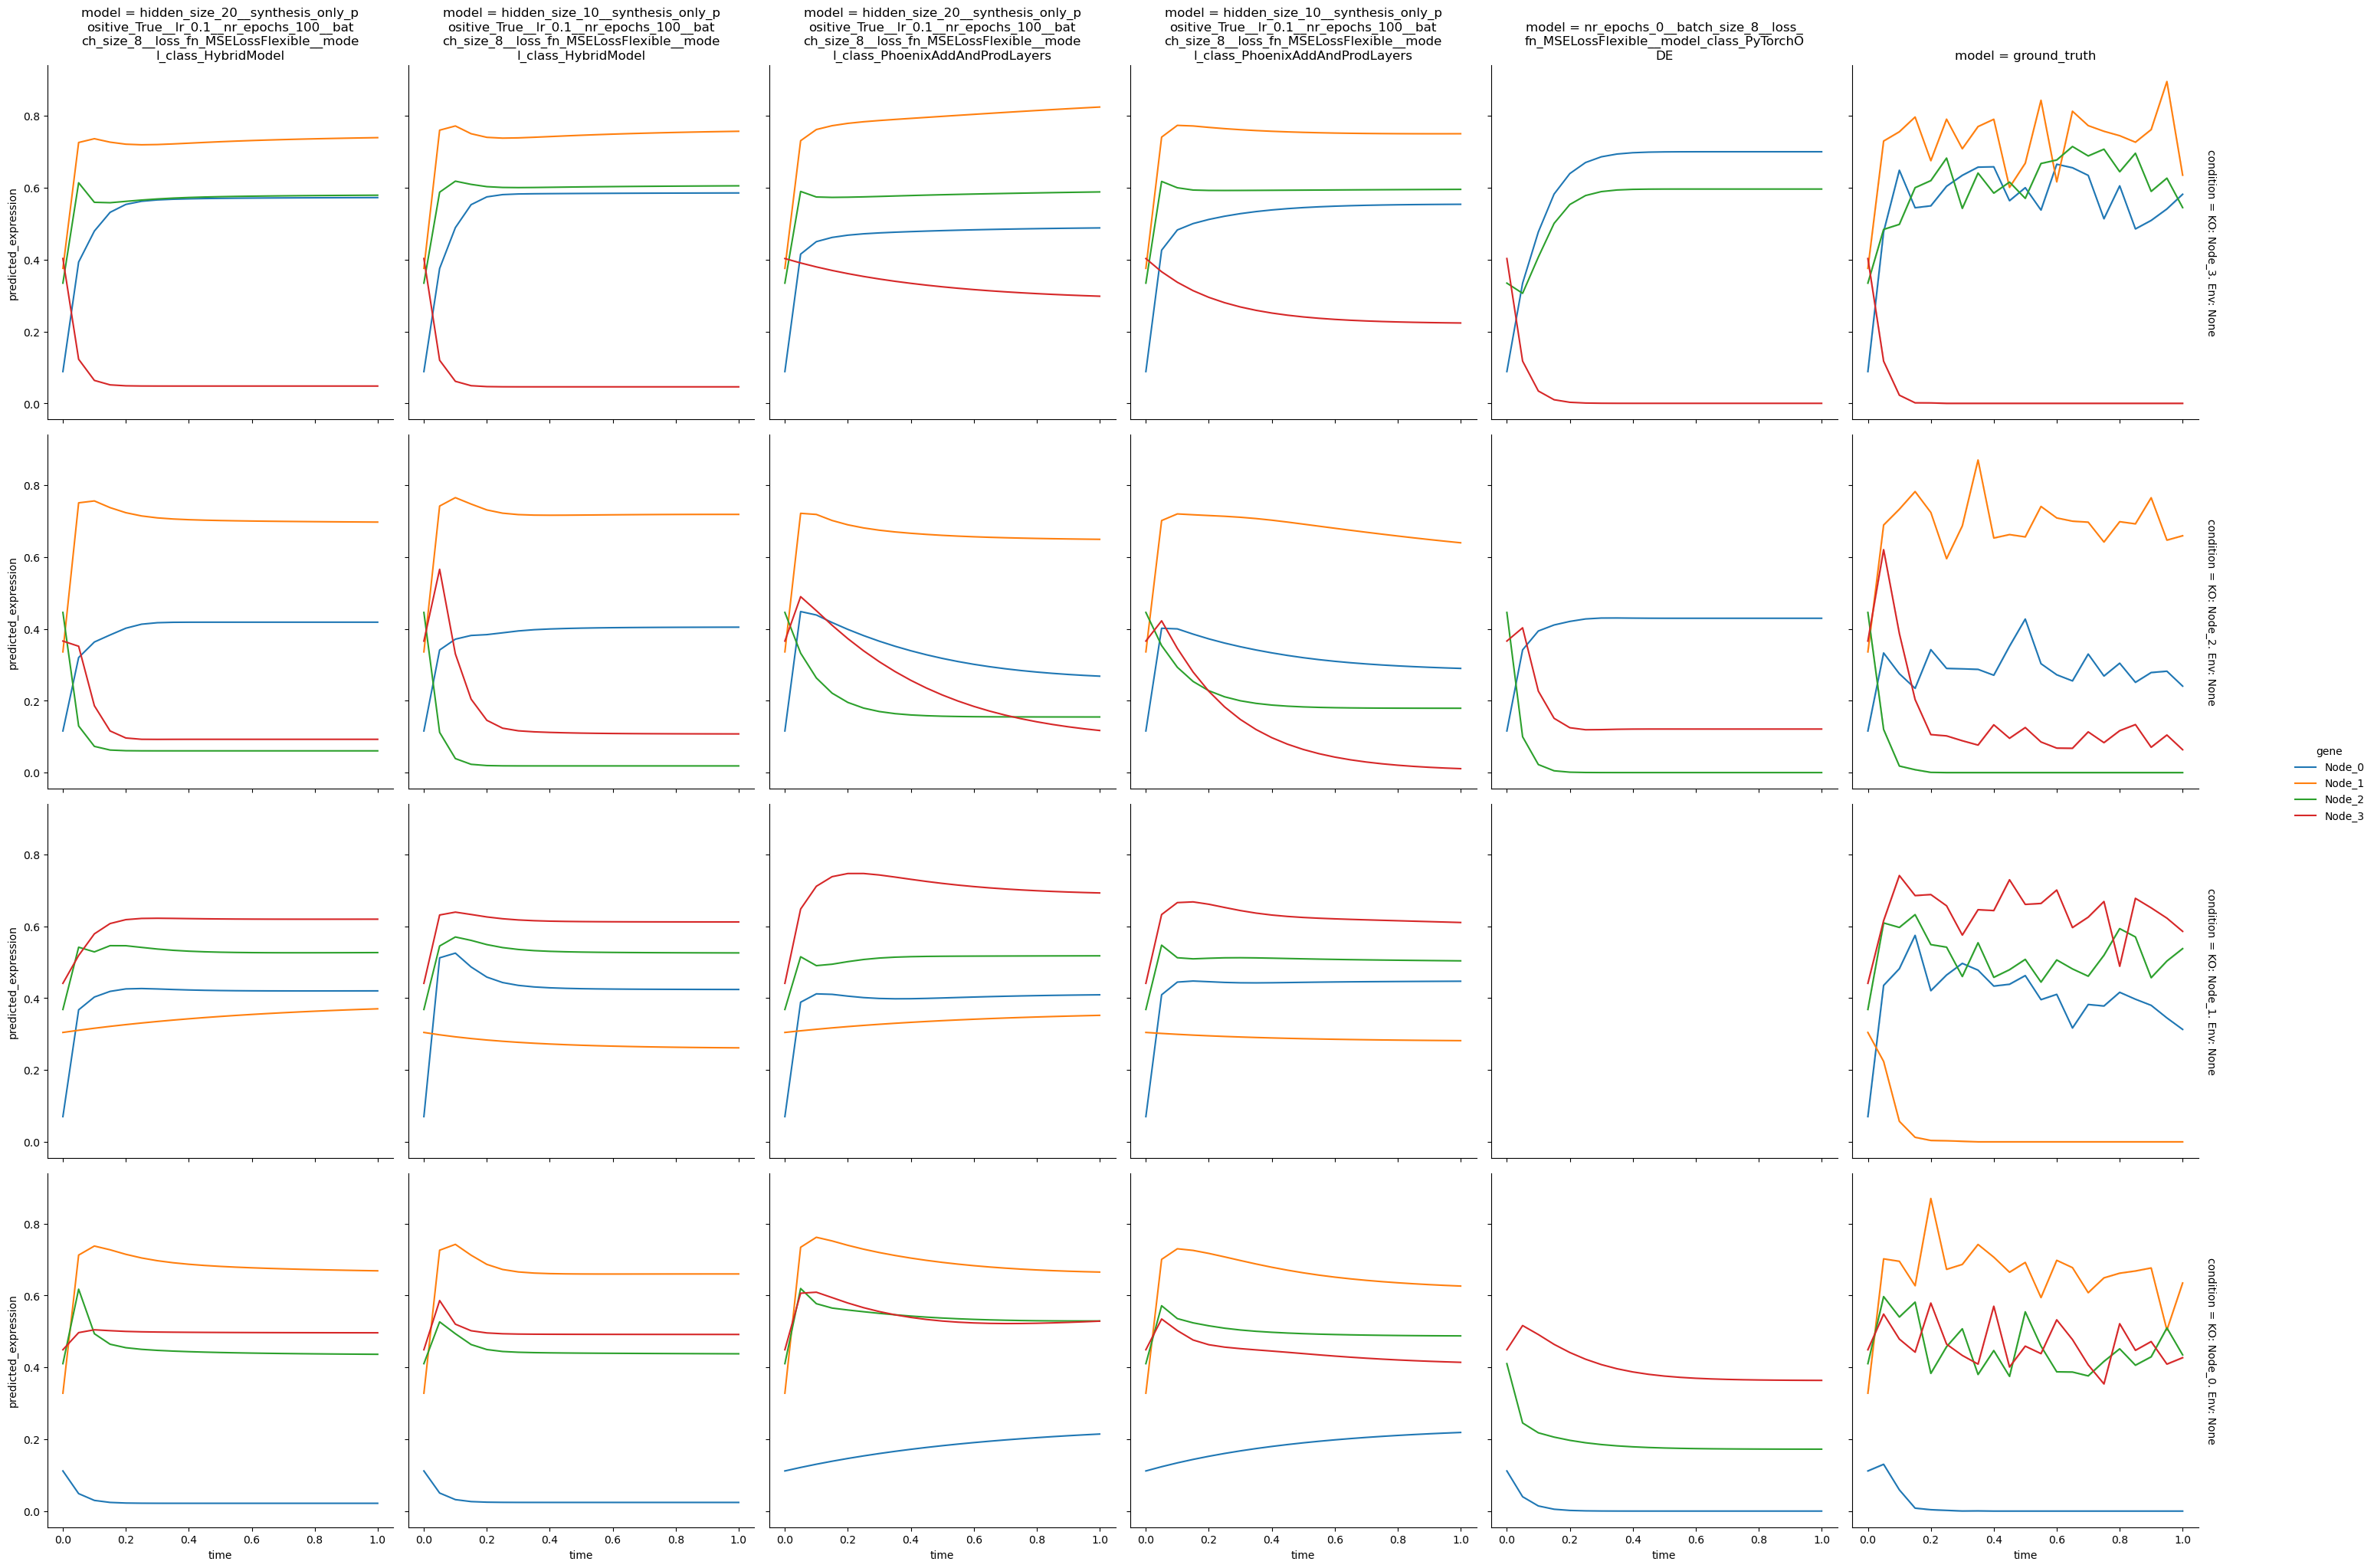

In [10]:
# FOr each of this knockout, plot predicted vs real for all model (for subset of genes)

# Plot for single KO
g = plot_model_plots(filtered_df_single_ko)
wrap_titles(g)

### Double KO

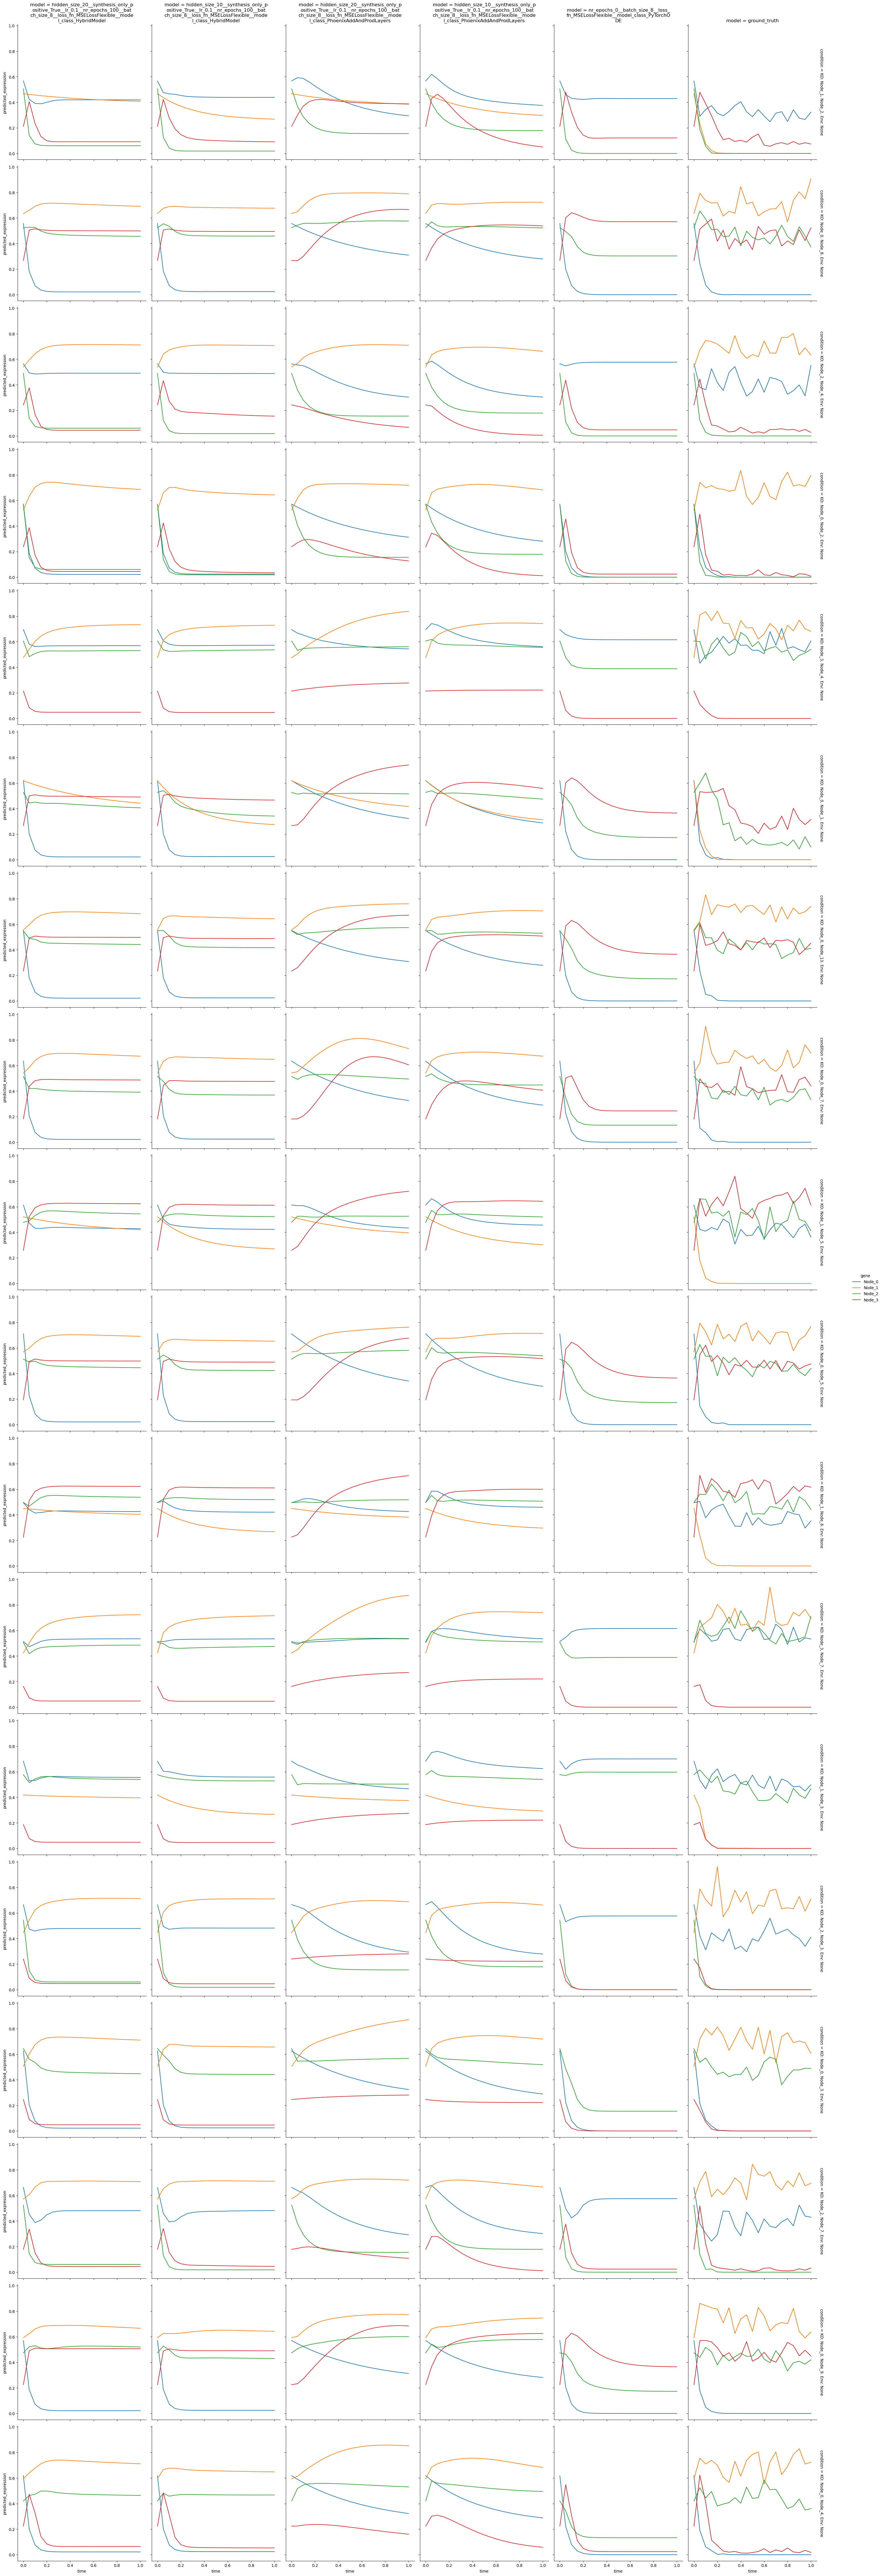

In [11]:
g = plot_model_plots(filtered_df_double_ko)
wrap_titles(g)

## Now the heatmaps

### Single KO

In [15]:
from matplotlib.colors import Normalize

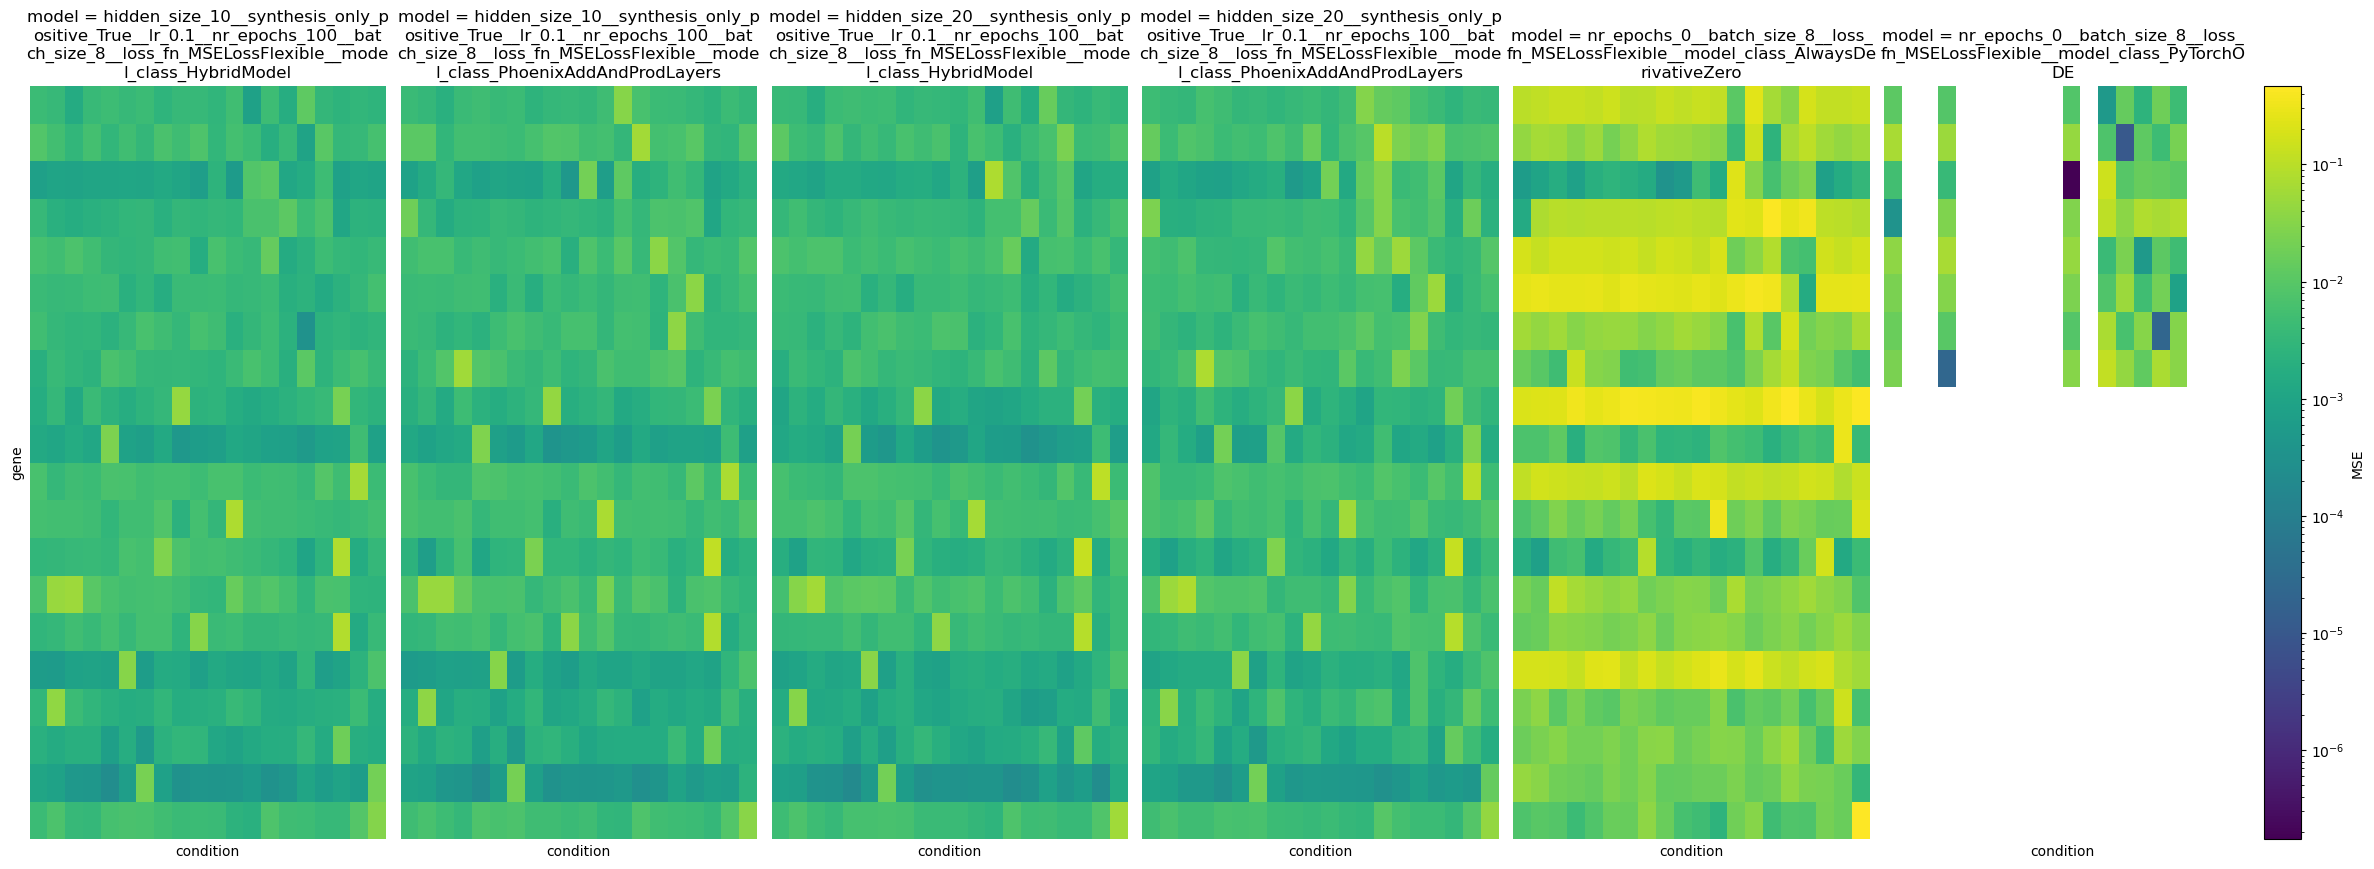

In [23]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_single_ko, robust_cmap=False)
wrap_titles(g)

### Double KO

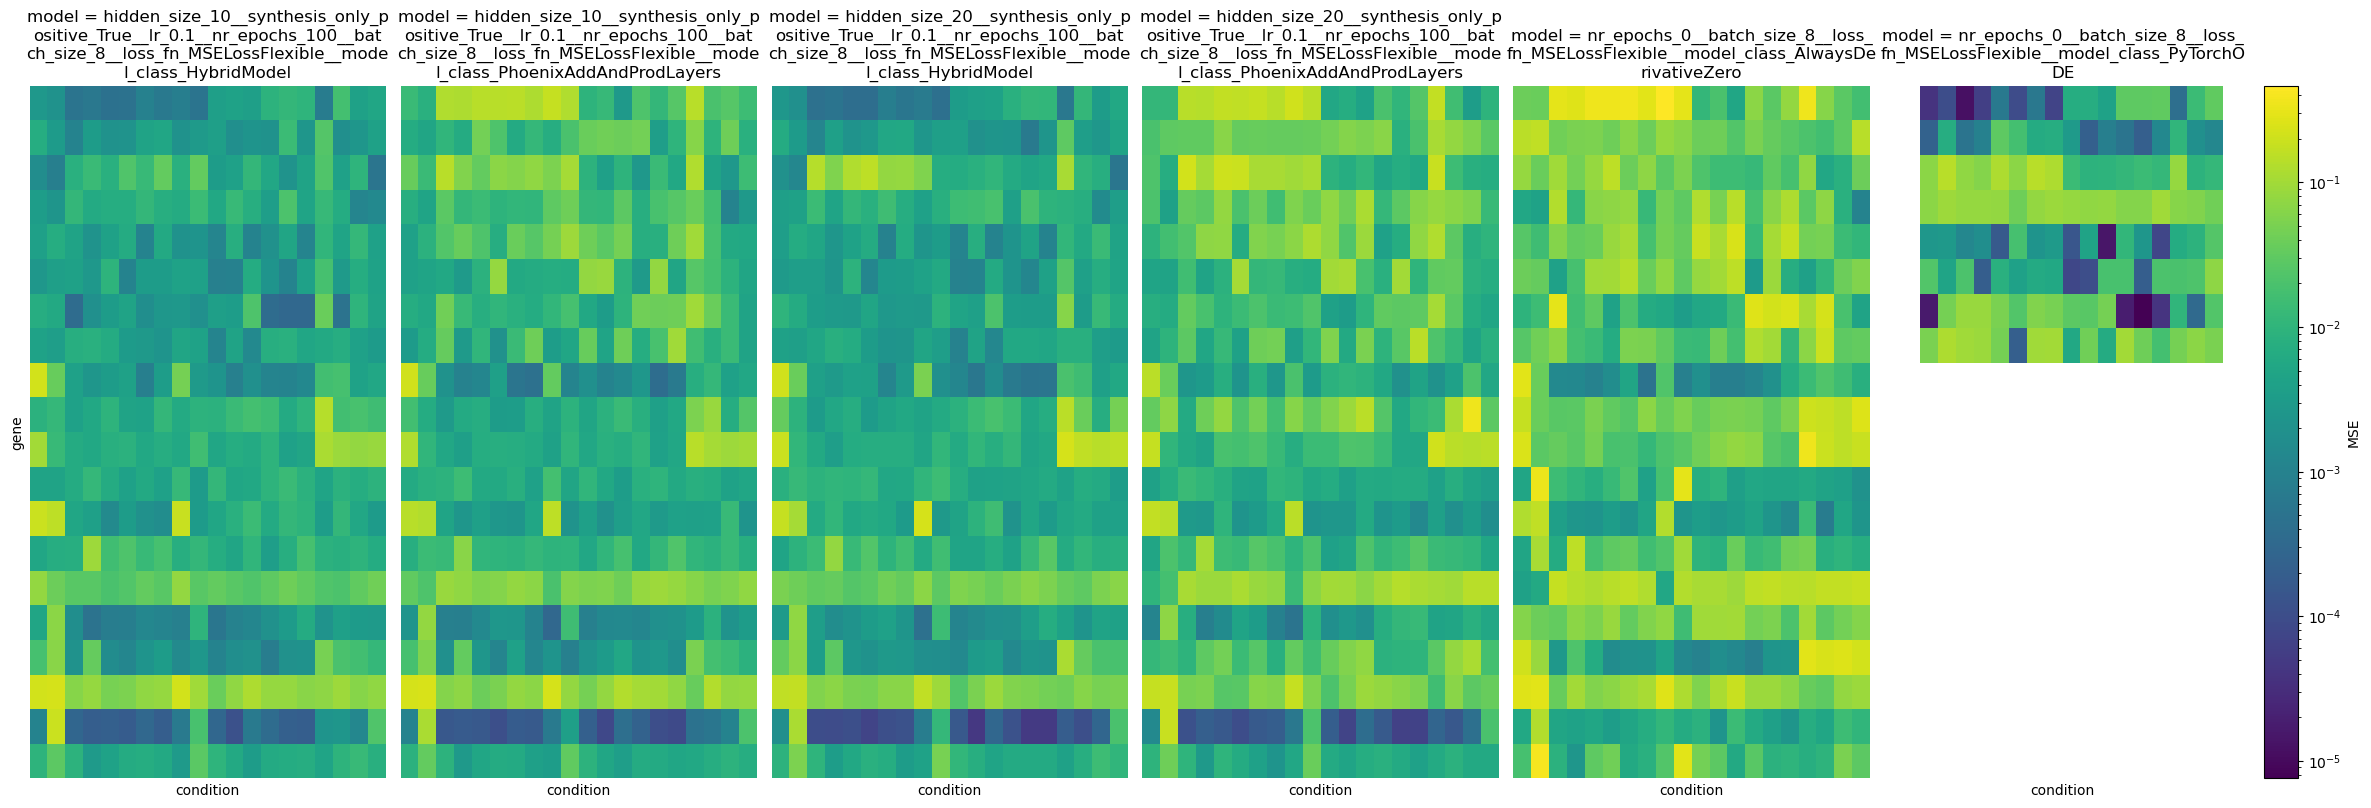

In [22]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_double_ko, robust_cmap=False)
wrap_titles(g)